# Missing-channel robustness
Models are trained on complete recordings. At test time, k random channels are 'lost' and filled with the average of the remaining channels. Task: AD vs CN.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
from src.features import load_spectra
from src.models import make_logreg, make_rf, make_cnn
from src.robustness import robustness_cv, as_bands, as_spectra
from src.config import RESULTS

spec = load_spectra()
runs = {"LogReg": (make_logreg, as_bands(spec)),
        "RandomForest": (make_rf, as_bands(spec)),
        "CNN": (make_cnn, as_spectra)}

curves = {}
for name, (make_model, to_input) in runs.items():
    curves[name] = robustness_cv(spec, make_model, to_input, ["AD", "CN"])
curves = pd.DataFrame(curves).round(3)
curves.index.name = "missing_channels"
print(curves)
curves.to_csv(RESULTS / "robustness_AD-CN.csv")

                  LogReg  RandomForest    CNN
missing_channels                             
0                  0.769         0.815  0.692
1                  0.769         0.812  0.680
2                  0.695         0.757  0.649
4                  0.732         0.742  0.615
6                  0.671         0.760  0.575
8                  0.640         0.705  0.578


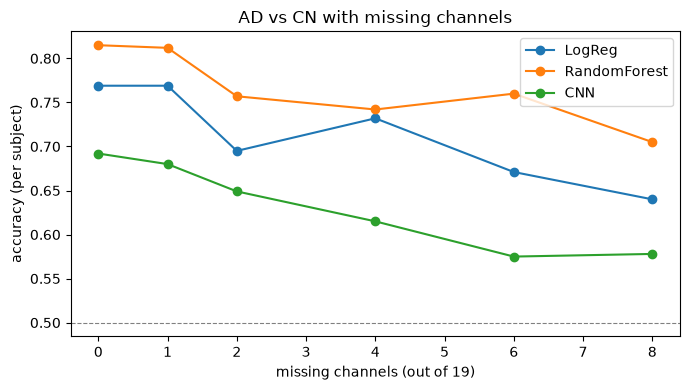

In [2]:
ax = curves.plot(marker="o", figsize=(7, 4))
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)      # chance level
ax.set_xlabel("missing channels (out of 19)")
ax.set_ylabel("accuracy (per subject)")
ax.set_title("AD vs CN with missing channels")
plt.tight_layout()
plt.savefig(RESULTS / "robustness_AD-CN.png", dpi=120)
plt.show()